# 1. 준비

In [1]:
import numpy as np
from sklearn import set_config

set_config(display="text")
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

import platform
import matplotlib.pyplot as plt

# 그래프 한글 깨짐 방지
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 선택하기

In [2]:
X, y = make_circles(n_samples=400, noise=0.1, factor=0.5, random_state=0)
print(X.shape)
print(X[:3])
print(y[:3])

(400, 2)
[[-0.53752884 -0.80641275]
 [-0.25421595 -0.14372127]
 [-0.23509005 -0.51474502]]
[0 1 1]


# 3. 선택한 데이터 시각화

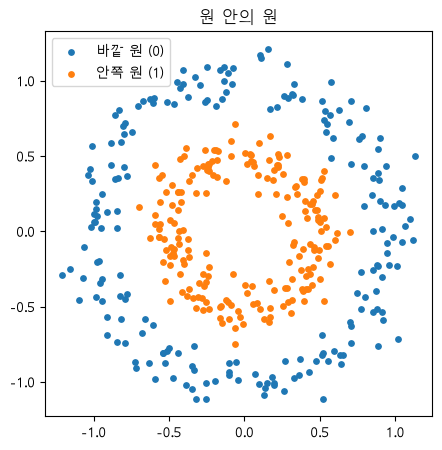

In [3]:
plt.figure(figsize=(5, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=15, label="바깥 원 (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:orange", s=15, label="안쪽 원 (1)")
plt.legend()
plt.title("원 안의 원")
plt.show()

# 4. 데이터 분리

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(len(X_train), len(X_test))

300 100


# 학습된 모델로 예측 결과를 이용하여 결계를 그려줌

In [5]:
def draw_boundary(model, title):
    xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(5, 5))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=15)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:orange", s=15)
    plt.title(title)
    plt.show()


# 머신러닝(학습 및 결과)

정확도: 0.45


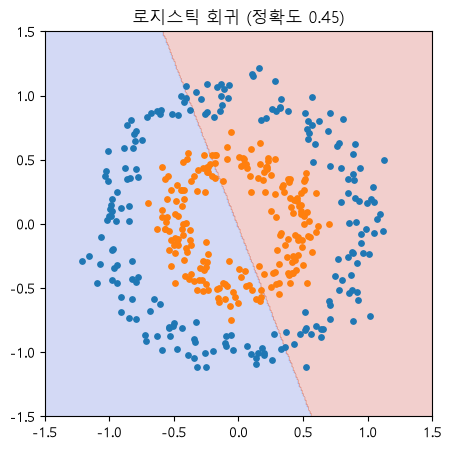

In [8]:
logi = LogisticRegression()
logi.fit(X_train, y_train)
print(f"정확도: {logi.score(X_test, y_test):.2f}")
draw_boundary(logi, f"로지스틱 회귀 (정확도 {logi.score(X_test, y_test):.2f})")

# 딥러닝(학습 및 결과)

(300, 2)
정확도: 1.00


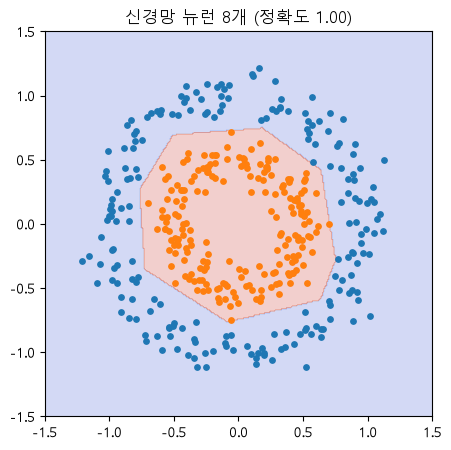

In [17]:
print(X_train.shape)
# 뉴런 : 8개. 학습을 위해 몇번 반복 : 3000
mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=3000, random_state=0)
mlp.fit(X_train, y_train)
print(f"정확도: {mlp.score(X_test, y_test):.2f}")
draw_boundary(mlp, f"신경망 뉴런 8개 (정확도 {mlp.score(X_test, y_test):.2f})")

# 반복횟수에 따른 손실확인

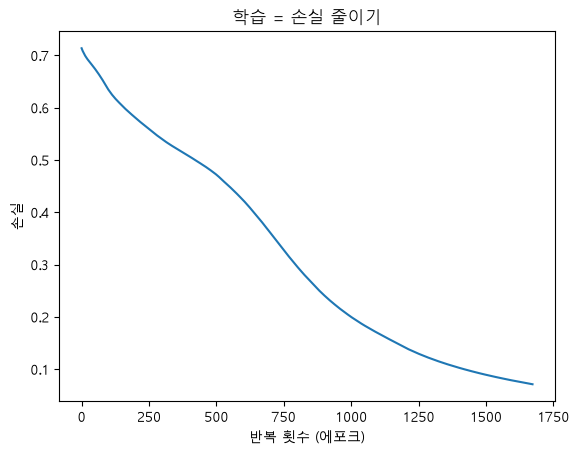

반복 횟수: 1674
처음 손실 0.714 → 마지막 손실 0.071


In [10]:
plt.plot(mlp.loss_curve_)
plt.xlabel("반복 횟수 (에포크)")
plt.ylabel("손실")
plt.title("학습 = 손실 줄이기")
plt.show()
print("반복 횟수:", mlp.n_iter_)
print(f"처음 손실 {mlp.loss_curve_[0]:.3f} → 마지막 손실 {mlp.loss_curve_[-1]:.3f}")

# 뉴런수에 따른 정확도

In [14]:
for hidden in [(1,), (2,), (3,), (8,), (8, 8), (3,2)]:
    m = MLPClassifier(hidden_layer_sizes=hidden, max_iter=3000, random_state=0)
    m.fit(X_train, y_train)
    print(f"은닉층 {str(hidden):7}: 정확도 {m.score(X_test, y_test):.2f}")

은닉층 (1,)   : 정확도 0.50
은닉층 (2,)   : 정확도 0.74
은닉층 (3,)   : 정확도 0.97
은닉층 (8,)   : 정확도 1.00
은닉층 (8, 8) : 정확도 1.00
은닉층 (3, 2) : 정확도 0.50


# 활성화 함수를 뺀 결과

활성화 함수 없음: 정확도 0.50


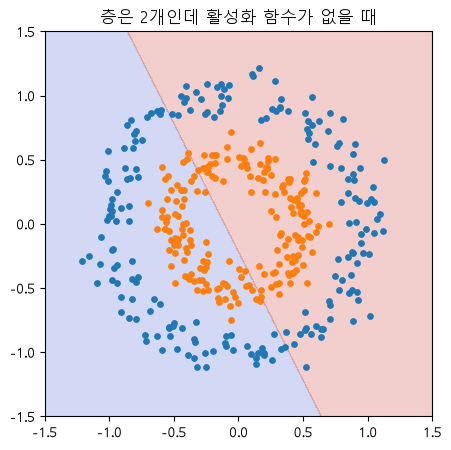

In [15]:
flat = MLPClassifier(hidden_layer_sizes=(8, 8), activation="identity", max_iter=3000, random_state=0)
flat.fit(X_train, y_train)
print(f"활성화 함수 없음: 정확도 {flat.score(X_test, y_test):.2f}")
draw_boundary(flat, "층은 2개인데 활성화 함수가 없을 때")